In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

Train samples: 60000, Test samples: 10000
Batches per epoch: 469
Batch image tensor shape: torch.Size([128, 1, 28, 28])


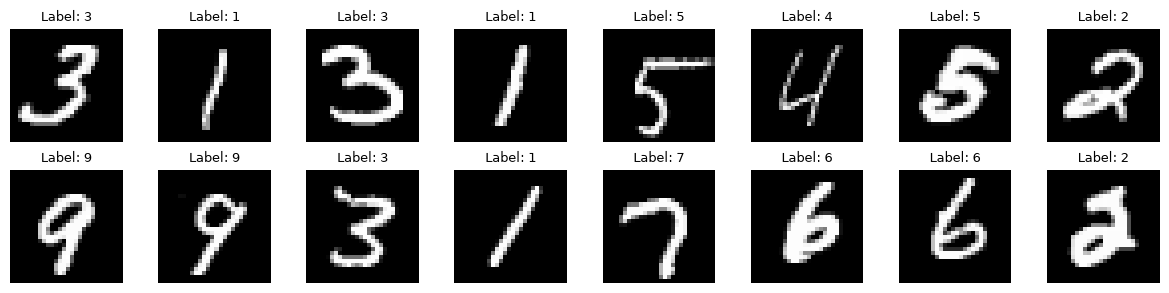

In [3]:


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))  
])

data_root = r"C:\Users\nevertheless\Desktop\oly\code\Generative-models\GAN\data"
train_dataset = datasets.MNIST(root=data_root, train=True, transform=transform, download = False)
test_dataset  = datasets.MNIST(root=data_root, train=False, transform=transform, download= False)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")
print(f"Batches per epoch: {len(train_loader)}")

images, labels = next(iter(train_loader))

print(f"Batch image tensor shape: {images.shape}")  

fig, axes = plt.subplots(nrows=2, ncols=8, figsize=(12, 3))
for idx, ax in enumerate(axes.flat):
    ax.imshow(images[idx].squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[idx].item()}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()



In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

device

'cuda'

In [5]:
T = 1000

betas = torch.linspace(1e-4 , 0.02 , T)
alpha = 1 - betas
alpha_bar = torch.cumprod(alpha, 0 ).to(device)

print("beta[0]:", betas[0].item())
print("alpha[0]:", alpha[0].item())
print("alpha_bar[0]:", alpha_bar[0].item())
print("alpha_bar[-1]:", alpha_bar[-1].item())


beta[0]: 9.999999747378752e-05
alpha[0]: 0.9998999834060669
alpha_bar[0]: 0.9998999834060669
alpha_bar[-1]: 4.0358307160204276e-05


In [6]:
def forward_diffusion(x0 , t):
    epsilon = torch.randn_like(x0)

    alpha_bar_t = alpha_bar[t].reshape(-1 , 1 , 1 , 1)
    mu = torch.sqrt(alpha_bar_t) * x0 
    sigma =  torch.sqrt(1-alpha_bar_t) * epsilon

    x_t = mu + sigma

    return x_t , epsilon


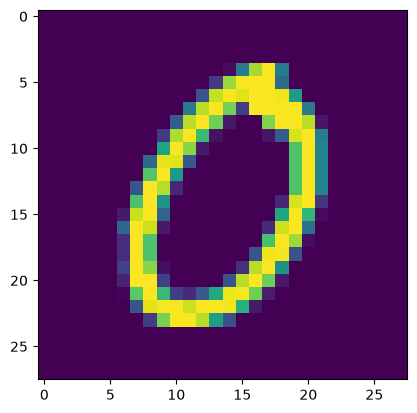

In [7]:
x0 = next(iter(train_loader))[0][0].squeeze(0)
plt.imshow(x0)

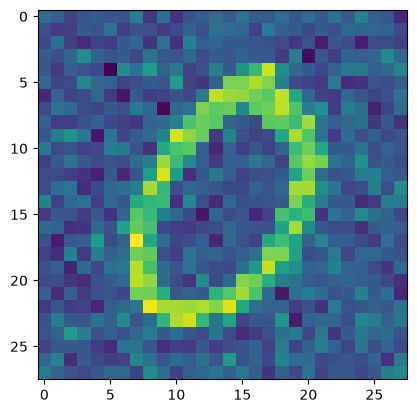

In [8]:
x_1 , _ = forward_diffusion(x0.to(device) , 100)
plt.imshow(x_1.reshape(28 , 28).cpu().numpy())

In [9]:
import torch.nn as nn

In [10]:
class ResidualBlock(nn.Module):

    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, padding=1
        )

        self.norm1 = nn.GroupNorm(8, out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, padding=1
        )

        self.norm2 = nn.GroupNorm(8, out_channels)

        self.act = nn.SiLU()

        self.time_mlp = nn.Linear(time_dim, out_channels)

        if in_channels != out_channels:
            self.shortcut = nn.Conv2d(
                in_channels, out_channels, kernel_size=1
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x, t_emb):

        residual = self.shortcut(x)

        h = self.conv1(x)
        h = self.norm1(h)

        time_emb = self.time_mlp(t_emb)
        time_emb = time_emb[:, :, None, None]

        h = h + time_emb
        h = self.act(h)

        h = self.conv2(h)
        h = self.norm2(h)

        return self.act(h + residual)         

In [11]:
class DownBlock(nn.Module):

    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.res1 = ResidualBlock(
            in_channels, out_channels, time_dim
        )

        self.res2 = ResidualBlock(
            out_channels, out_channels, time_dim
        )

        self.downsample = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=4, stride=2, padding=1
        )

    def forward(self, x, t_emb):

        x = self.res1(x, t_emb)
        x = self.res2(x, t_emb)

        skip = x

        x = self.downsample(x)

        return x, skip

In [12]:
class MiddleBlock(nn.Module):

    def __init__(self, channels, time_dim):
        super().__init__()

        self.res1 = ResidualBlock(
            channels, channels, time_dim
        )

        self.res2 = ResidualBlock(
            channels, channels, time_dim
        )

    def forward(self, x, t_emb):

        x = self.res1(x, t_emb)
        x = self.res2(x, t_emb)

        return x


In [13]:
class UpBlock(nn.Module):

    def __init__(self, in_channels, skip_channels,
                 out_channels, time_dim):
        super().__init__()

        self.upsample = nn.ConvTranspose2d(
            in_channels, out_channels,
            kernel_size=4, stride=2, padding=1
        )

        self.res1 = ResidualBlock(
            out_channels + skip_channels,
            out_channels,
            time_dim
        )

        self.res2 = ResidualBlock(
            out_channels, out_channels, time_dim
        )

    def forward(self, x, skip, t_emb):

        x = self.upsample(x)

        x = torch.cat([x, skip], dim=1)

        x = self.res1(x, t_emb)
        x = self.res2(x, t_emb)

        return x

In [14]:
class NoisePredictor(nn.Module):

    def __init__(self, in_channels=1, out_channels=1,
                 time_dim=128):

        super().__init__()

        self.time_dim = time_dim

        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input_conv = nn.Conv2d(
            in_channels, 64, kernel_size=3, padding=1
        )

        self.d1 = DownBlock(64, 128, time_dim)
        self.d2 = DownBlock(128, 256, time_dim)

        self.middle = MiddleBlock(256, time_dim)

        self.u1 = UpBlock(
            256, 256, 128, time_dim
        )

        self.u2 = UpBlock(
            128, 128, 64, time_dim
        )
 
        self.final = nn.Sequential(
            nn.GroupNorm(8, 64),
            nn.SiLU(),
            nn.Conv2d(64, out_channels, kernel_size=3, padding=1)
        )

    def forward(self, x, t):

        t_emb = sinusoidal_time_embedding(
            t, self.time_dim
        )

        t_emb = self.time_mlp(t_emb)

        x = self.input_conv(x)

        x, skip1 = self.d1(x, t_emb)

        x, skip2 = self.d2(x, t_emb)

        x = self.middle(x, t_emb)

        x = self.u1(x, skip2, t_emb)

        x = self.u2(x, skip1, t_emb)

        return self.final(x)

In [15]:
import math

def sinusoidal_time_embedding(t, dim):
    half_dim = dim // 2

    frequencies = torch.exp(
        -math.log(10000) *
        torch.arange(half_dim, device=t.device).float() / half_dim
    )

    angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)

    embedding = torch.cat([
        torch.sin(angles),
        torch.cos(angles)
    ], dim=1)

    return embedding

In [16]:
model = NoisePredictor().to(device)

model(next(iter(train_loader))[0].to(device) , torch.randint(0 , T , (128,) , device=device)).to(device).shape

torch.Size([128, 1, 28, 28])

In [17]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [18]:
next(iter(train_loader))[0].shape

torch.Size([128, 1, 28, 28])

In [22]:
def train_loop(dataloader, model, loss_fn, optimizer):
    model.train()
    for batch, (X, _) in enumerate(dataloader):
        X = X.to(device)
        t = torch.randint(0 , T , (X.shape[0],) , device=device)

        X_t , eps = forward_diffusion(X , t)

        eps_pred = model(X_t , t)

        loss = loss_fn(eps , eps_pred)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}")

for t in range(20):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer)
    # test_loop(test_loader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 0.074336
loss: 0.037994
loss: 0.030851
loss: 0.032641
loss: 0.028963
Epoch 2
-------------------------------
loss: 0.030809
loss: 0.033436
loss: 0.027441
loss: 0.029601
loss: 0.027025
Epoch 3
-------------------------------
loss: 0.025548
loss: 0.025713
loss: 0.027315
loss: 0.025744
loss: 0.034636
Epoch 4
-------------------------------
loss: 0.020902
loss: 0.023876
loss: 0.025265
loss: 0.022543
loss: 0.025285
Epoch 5
-------------------------------
loss: 0.025398
loss: 0.028660
loss: 0.032066
loss: 0.021204
loss: 0.025297
Epoch 6
-------------------------------
loss: 0.022131
loss: 0.026397
loss: 0.023088
loss: 0.023807
loss: 0.023480
Epoch 7
-------------------------------
loss: 0.026385
loss: 0.021110
loss: 0.025805
loss: 0.025247
loss: 0.017972
Epoch 8
-------------------------------
loss: 0.020467
loss: 0.022691
loss: 0.023356
loss: 0.017854
loss: 0.020397
Epoch 9
-------------------------------
loss: 0.023596
loss: 0.022014
loss: 0.02

t=100 | Noise prediction MSE: 0.061213
t=500 | Noise prediction MSE: 0.021662
t=900 | Noise prediction MSE: 0.000416


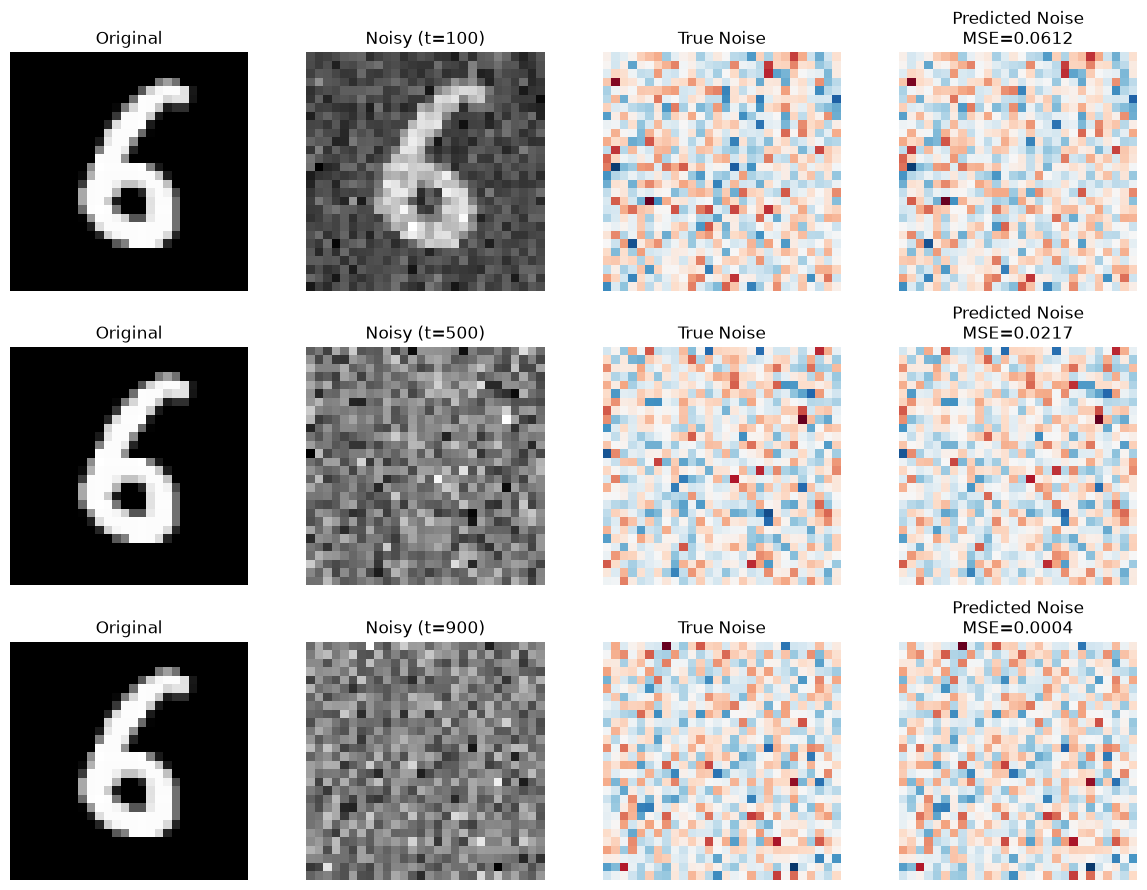

In [25]:
test_timesteps = [100, 500, 900]

images, _ = next(iter(train_loader))
x0 = images[:1].to(device)  

model.eval()

with torch.no_grad():
    fig, axes = plt.subplots(
        len(test_timesteps), 4, figsize=(12, 3 * len(test_timesteps))
    )

    for row, t_value in enumerate(test_timesteps):
        t = torch.tensor([t_value], dtype=torch.long, device=device)

        x_t, eps = forward_diffusion(x0, t)

        eps_pred = model(x_t, t)

        mse = torch.nn.functional.mse_loss(eps_pred, eps).item()

        original = x0[0, 0].cpu()
        noisy = x_t[0, 0].cpu()
        true_noise = eps[0, 0].cpu()
        predicted_noise = eps_pred[0, 0].cpu()

        axes[row, 0].imshow(original, cmap="gray")
        axes[row, 0].set_title("Original")

        axes[row, 1].imshow(noisy, cmap="gray")
        axes[row, 1].set_title(f"Noisy (t={t_value})")

        vmax = max(true_noise.abs().max().item(),
                   predicted_noise.abs().max().item())

        axes[row, 2].imshow(
            true_noise, cmap="RdBu_r", vmin=-vmax, vmax=vmax
        )
        axes[row, 2].set_title("True Noise")

        axes[row, 3].imshow(
            predicted_noise, cmap="RdBu_r", vmin=-vmax, vmax=vmax
        )
        axes[row, 3].set_title(f"Predicted Noise\nMSE={mse:.4f}")

        for ax in axes[row]:
            ax.axis("off")

        print(f"t={t_value:3d} | Noise prediction MSE: {mse:.6f}")

    plt.tight_layout()
    plt.show()


In [39]:
@torch.no_grad()
def sample(model):
    model.eval()

    x = torch.randn(1 , 1 , 28 , 28 , device = device)
    for t in range(T-1 , -1 , -1):

        time = torch.tensor([t] , device = device)
        eps_theta = model(x , time)
        sigma_t = 0 if t == 0 else torch.sqrt(betas[t])


        z = torch.randn_like(x , device = device)

        x = (x - (betas[t] / (torch.sqrt(1-alpha_bar[t])) * eps_theta)) / torch.sqrt(alpha[t]) + sigma_t * z

    return x

In [40]:
num_samples = 16

samples = []

for i in range(num_samples):
    img = sample(model)
    samples.append(img.cpu())

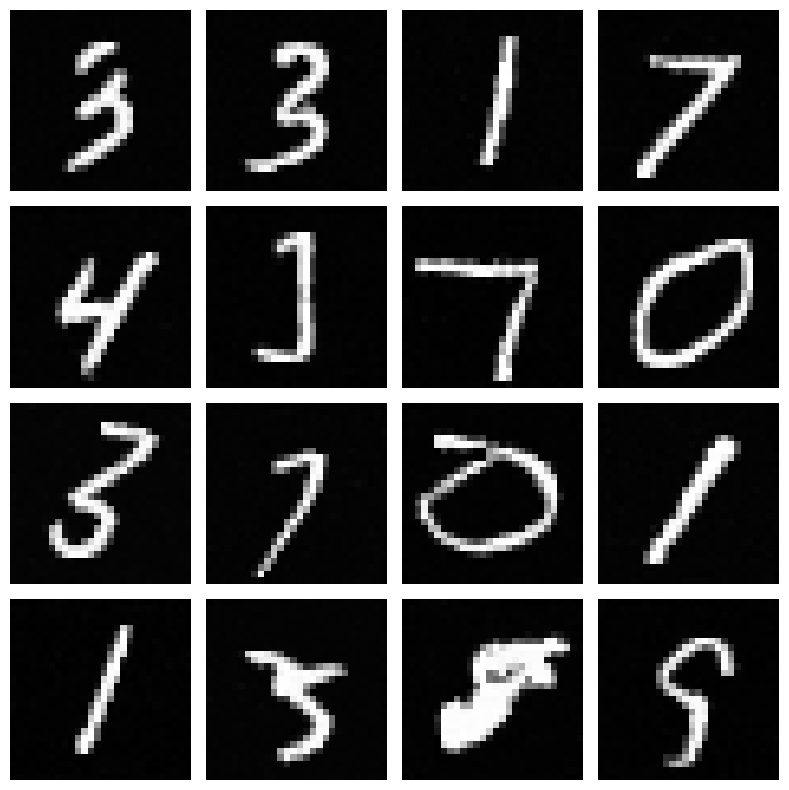

In [41]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    img = samples[i].squeeze()

    ax.imshow(img, cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()